# Career age comparisons

**David H. Collin | STAT 159 | Fall 2026**

The `tennisage` package retrieves a player's singles career from [Tennis Abstract](https://www.tennisabstract.com/) and plots player age against the difference between player and opponent ages. These examples use the two public functions, `get_career_data()` and `plot_age_difference()`, for Serena Williams and Rafael Nadal.

Install the package from the repository root with `python -m pip install -e ".[dev,notebook]"`, then open this notebook in that environment. Saved outputs can be viewed without internet access. Rerunning the retrieval cells downloads current data and may change the results.

In [1]:
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from tennisage import get_career_data, plot_age_difference

pd.Series({name: version(name) for name in ["tennisage", "pandas", "matplotlib"]}, name="Version")

tennisage      0.1.0
pandas         2.3.3
matplotlib    3.11.2
Name: Version, dtype: object

In [2]:
working_directory = Path.cwd()
project_root = working_directory if (working_directory / "pyproject.toml").is_file() else working_directory.parent
if not (project_root / "pyproject.toml").is_file():
    raise FileNotFoundError("Run this notebook from the repository root or its examples directory.")
figure_directory = project_root / "examples" / "figures"
figure_directory.mkdir(parents=True, exist_ok=True)

## Retrieve two careers

Player names may be spaced, compact, or written with different capitalization. Each call returns the same cleaned column structure, even when the source represents opponent information differently. The returned data retain matches that are excluded from plotting, together with their exclusion reasons.

Ages are measured in years. Birth-date calculations use elapsed days divided by 365.25; reported opponent ages are retained when supplied by the source. Tournament dates approximate match dates. See the [data dictionary](../docs/data_dictionary.md) for details.

In [3]:
serena = get_career_data("serena williams")
rafa = get_career_data("RafaelNadal")
retrieved_at = datetime.now(timezone.utc).replace(microsecond=0).isoformat()
print(f"Retrieved at {retrieved_at}")

Retrieved at 2026-11-08T05:40:14+00:00


In [4]:
summaries = []
for frame in [serena, rafa]:
    summaries.append({
        "Player": frame["player_name"].iloc[0],
        "Records": len(frame),
        "Plotted": int(frame["included_in_plot"].sum()),
        "Excluded": int((~frame["included_in_plot"]).sum()),
        "First tournament": frame["tournament_date"].min().date().isoformat(),
        "Last tournament": frame["tournament_date"].max().date().isoformat(),
    })
pd.DataFrame(summaries).set_index("Player")

,Records,Plotted,Excluded,First tournament,Last tournament
Player,,,,,
Serena Williams,1039,1015,24,1995-10-30,2026-06-29
Rafael Nadal,1431,1413,18,2001-09-10,2024-11-19


## Serena Williams

The horizontal coordinate is the player's age; the vertical coordinate is `player_age - opponent_age`. Positive values indicate that the player was older. Cyan points are wins and purple points are losses. The gray horizontal line marks equal ages. Every eligible record is plotted, without an article-date cutoff or individual match annotations.

,tournament_date,tournament,opponent,result,player_age,opponent_age,age_difference
0,1995-10-30,Canadian Open,Anne Miller,L,14.092,18.776,-4.684
1,1997-03-07,Indian Wells,Alexia Dechaume Balleret,L,15.444,26.845,-11.400
2,1997-08-04,Manhattan Beach,Magui Serna,L,15.855,18.428,-2.574
3,1997-08-04,Manhattan Beach,Amanda Basica,W,15.855,19.124,-3.269
4,1997-08-04,Manhattan Beach,Tamarine Tanasugarn,W,15.855,20.197,-4.342


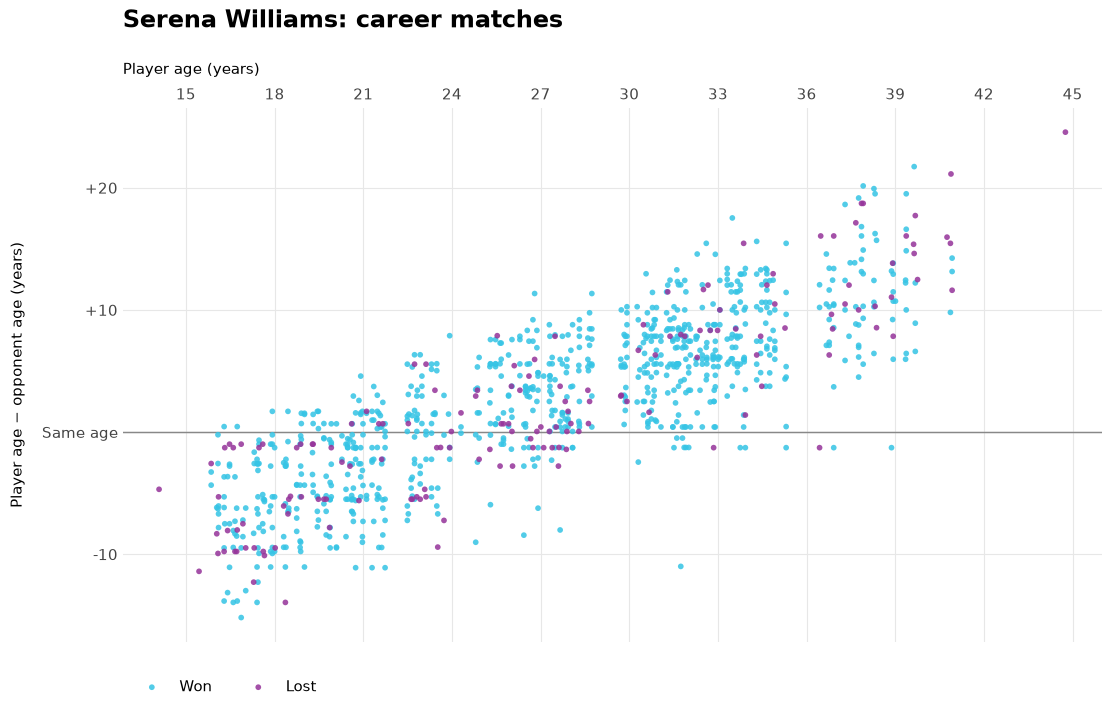

In [5]:
columns = ["tournament_date", "tournament", "opponent", "result", "player_age", "opponent_age", "age_difference"]
display(serena.loc[:, columns].head().round(3))
serena_axes = plot_age_difference(serena)
serena_axes.figure.savefig(figure_directory / "serena_age_difference.png", dpi=180, bbox_inches="tight")
plt.show()

## Rafael Nadal

The same calls handle the men's data. Axis limits adapt to the retrieved career. The returned Matplotlib axes object can also be used to change labels, adjust limits, or save the figure in another format.

,tournament_date,tournament,opponent,result,player_age,opponent_age,age_difference
0,2001-09-10,Spain F10,Guillermo Platel,L,15.272,22.264,-6.992
1,2001-09-17,Seville CH,Stefano Galvani,L,15.291,24.290,-8.999
2,2001-09-17,Seville CH,Israel Matos Gil,W,15.291,18.760,-3.469
3,2001-10-15,Spain 7 2,Gabriel Trujillo Soler,L,15.368,22.042,-6.675
4,2001-10-15,Spain 7 1,Juan Giner,L,15.368,23.217,-7.849


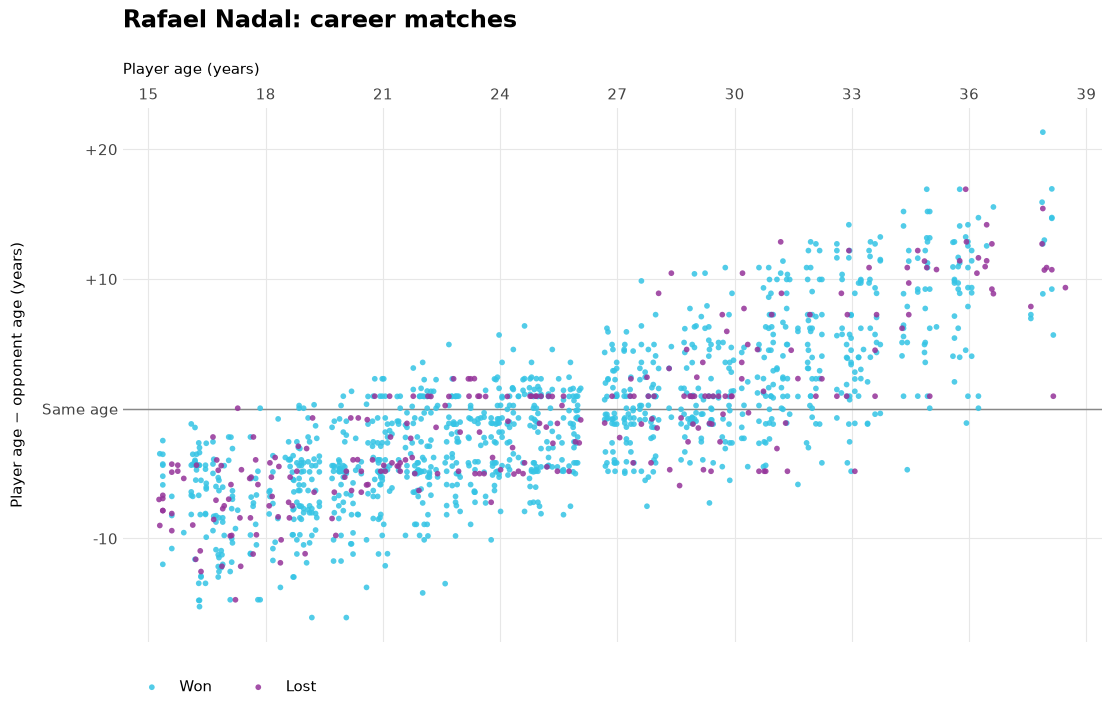

In [6]:
display(rafa.loc[:, columns].head().round(3))
rafa_axes = plot_age_difference(rafa)
rafa_axes.figure.savefig(figure_directory / "rafael_age_difference.png", dpi=180, bbox_inches="tight")
plt.show()

## Matches excluded from plotting

Stand-alone walkovers and defaults are excluded, as are records missing the opponent age needed for the vertical coordinate. Retirements remain eligible when the ages are available. Filtering is handled by `plot_age_difference()` using `included_in_plot`; the original data frames retain the excluded rows.

In [7]:
excluded = pd.concat([
    frame.loc[~frame["included_in_plot"], ["player_name", "exclusion_reason"]]
    for frame in [serena, rafa]
], ignore_index=True)
excluded.groupby(["player_name", "exclusion_reason"]).size().rename("Matches").to_frame()

,,Matches
player_name,exclusion_reason,
Rafael Nadal,walkover_or_default,18
Serena Williams,walkover_or_default,24


## Unknown player

An unrecognized name raises a `ValueError` that identifies the requested name. The exception is caught here so its message can be displayed. Network failures instead raise `ConnectionError`.

In [8]:
try:
    get_career_data("GastonSanchez")
except ValueError as error:
    print(error)

No player named 'GastonSanchez' was found in Tennis Abstract's player index.


## Reproduce the figures

Restart the kernel and run all cells to retrieve the current records and overwrite `examples/figures/serena_age_difference.png` and `examples/figures/rafael_age_difference.png`. The notebook records the retrieval time and installed package versions above. Counts and date ranges describe the records returned by Tennis Abstract; later source updates can change them.

The automated test suite runs separately with `python -m pytest -q`. It uses local career samples and mocked HTTP responses, with network sockets disabled. This notebook is not part of that test suite.

Source: [Tennis Abstract](https://www.tennisabstract.com/), by Jeff Sackmann. Plot structure follows the age comparison used in STAT 159 HW2.